# Địa hình thực để nhóm chọn hướng khảo sát

**Đề xuất khảo sát — chưa chọn site, ROI hay sản phẩm cuối cùng.** Mở output đã nhúng để xem ngay. Mỗi site có mẫu DEM PGDA 78 thật 2,5 × 2,5 km quanh tâm Data Book, native 5 m/pixel; phép đọc dùng thêm halo một pixel. Chín site được hiển thị cùng tỷ lệ mặt đất. Các mẫu không bao phủ toàn site/ROI và không đủ để xác định chân trời xa.

Notebook gồm bảng coverage/nguồn, hình độ cao tương đối, hillshade tổng hợp, độ dốc proxy và panel chi tiết có mask. **Hillshade không phải chiếu sáng nhiệm vụ.** Độ dốc là phép sai phân trên DEM, chưa phải lớp slope hoặc bằng chứng an toàn hạ cánh. Những số horizon/p95 lịch sử đang có vấn đề tái lập được giữ trong notebook cũ; không dùng chúng để xếp hạng tại đây.

Nguồn: [PGDA 78](https://pgda.gsfc.nasa.gov/products/78), [NASA Data Book 2025](https://ntrs.nasa.gov/api/citations/20250002845/downloads/M2M-30044%20Lunar%20Surface%20Data%20Book%20Baseline_Final.pdf). Metadata của lần đọc nằm trong [manifest](evidence/terrain-preview-manifest.json). Xem [phiếu quyết định](../docs/predecision-review.md).

**Chạy lại:** cần Python, Jupyter, NumPy, pandas, Matplotlib, Rasterio. Không tự cài thư viện. Lần đầu cần mạng nếu `FETCH_MISSING=True`: đọc đúng 502×502 pixel mỗi source, HTTP Range có thể truyền nhiều byte hơn số pixel do layout TIFF. Cache nhỏ ở `data/preview/` bị Git bỏ qua. Output và manifest đã review được lưu trong Git; không chứa full raster. Dùng `FETCH_MISSING=False` nếu chỉ muốn chạy với cache đã có. Cache kiểm tra hash; xóa một file cache là yêu cầu đọc lại source tương ứng, không tự ghi đè manifest đã review.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib import patheffects
from IPython.display import display

In [2]:
from pathlib import Path
from datetime import datetime, timezone
import hashlib, json, math, os
import numpy as np
import pandas as pd
import rasterio
from rasterio.windows import Window
from rasterio.warp import transform as transform_coords
import urllib.request

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'docs/data-mining-plan.md').exists())
CACHE = ROOT/'data/preview'
CACHE.mkdir(parents=True, exist_ok=True)
FETCH_MISSING = True  # Only 502 x 502 pixels per site; no full-raster acquisition.
N = 500  # 2,500 x 2,500 metres at native 5 m; one-pixel derivative halo.
BASE = 'https://pgda.gsfc.nasa.gov/data/LOLA_5mpp'
# Reference coordinates and full five-layer sizes from the reviewed inventory.
SITES = [
 ('Site01',-89.4632,-137.49,204903950,'available'),
 ('Site04',-89.7668,-171.87,204903932,'available'),
 ('Site06',-85.4381,37.36667,320127929,'listed link returned not-found'),
 ('Site07',-88.811,123.6901,204903942,'available'),
 ('Site11',-88.6834,-67.9321,204903940,'available'),
 ('Site20',-85.4266,31.74276,204903930,'no verified ROI'),
 ('Site23',-85.9948,-0.23578,352933976,'no verified ROI'),
 ('Site42',-85.8296,-116.322,320127973,'no ROI link listed'),
 ('Haworth',-86.7639,-22.777,710618745,'no ROI link listed'),
]

def digest(z):
    return hashlib.sha256(np.ascontiguousarray(z,dtype='<f4').tobytes()).hexdigest()

import io, time

class RangeFile(io.RawIOBase):
    """Seekable read-only source: validate 206 bodies; reject whole-file fallback."""
    def __init__(self,url,size,blocks,traffic):
        super().__init__(); self.url=url; self.size=size; self.blocks=blocks; self.traffic=traffic; self.pos=0
        self.block_size=512*1024
    def readable(self): return True
    def seekable(self): return True
    def tell(self): return self.pos
    def seek(self,offset,whence=0):
        self.pos=int(offset if whence==0 else self.pos+offset if whence==1 else self.size+offset)
        if self.pos<0: raise ValueError('Negative offset')
        return self.pos
    def read(self,n=-1):
        if n<0: raise ValueError('Unbounded source read disabled')
        end=min(self.size,self.pos+n); chunks=[]
        while self.pos<end:
            idx=self.pos//self.block_size; start=idx*self.block_size; stop=min(start+self.block_size,self.size)-1
            if idx not in self.blocks:
                last=None
                for attempt in range(3):
                    if self.traffic['body_bytes']+(stop-start+1)>24*1024**2:
                        raise IOError('Per-site HTTP body budget exceeded (24 MiB including retries)')
                    try:
                        req=urllib.request.Request(self.url,headers={'User-Agent':'Mozilla/5.0','Range':f'bytes={start}-{stop}'})
                        with urllib.request.urlopen(req,timeout=25) as r:
                            if r.status!=206 or r.headers.get('Content-Range')!=f'bytes {start}-{stop}/{self.size}':
                                raise IOError('Source ignored/misreported requested byte range')
                            body=r.read(stop-start+2)
                            self.traffic['body_bytes']+=len(body)
                            if len(body)!=stop-start+1: raise IOError('Truncated or oversized byte range')
                            self.blocks[idx]=body; self.traffic['ranges'].append([start,stop]); break
                    except Exception as exc:
                        last=exc
                        if attempt==2: raise IOError(f'Failed range {start}-{stop}: {exc}') from exc
                        time.sleep(1)
            data=self.blocks[idx]; take=min(end-self.pos,stop-self.pos+1)
            chunks.append(data[self.pos-start:self.pos-start+take]); self.pos+=take
        return b''.join(chunks)
    def readinto(self,b):
        d=self.read(len(b)); b[:len(d)]=d; return len(d)


def load_preview(site,lat,lon):
    f=CACHE/f'{site}-500.npz'
    if f.exists():
        with np.load(f,allow_pickle=False) as d:
            z=d['elevation_m']; meta=json.loads(str(d['metadata']))
        if meta['array_sha256'] != digest(z): raise ValueError(f'Cache checksum mismatch: {site}')
        if meta['reference_lat_lon'] != [lat,lon] or z.shape != (N+2,N+2):
            raise ValueError(f'Cache geometry mismatch: {site}')
        return z,meta
    if not FETCH_MISSING: raise FileNotFoundError(f'{f}; enable FETCH_MISSING for bounded source reads')
    print(f'Reading {site}...',flush=True)
    url=f'{BASE}/{site}/{site}_final_adj_5mpp_surf.tif'
    with urllib.request.urlopen(urllib.request.Request(url,method='HEAD',headers={'User-Agent':'Mozilla/5.0'}),timeout=30) as h:
        head={k:h.headers.get(k) for k in ['Content-Length','ETag','Last-Modified','Content-Type']}
    if 'tiff' not in str(head['Content-Type']).lower(): raise ValueError(f'Not a TIFF endpoint: {site}')
    opts=dict(GDAL_DISABLE_READDIR_ON_OPEN='EMPTY_DIR',CPL_VSIL_CURL_ALLOWED_EXTENSIONS='.tif',
              GDAL_HTTP_USERAGENT='Mozilla/5.0',GDAL_HTTP_TIMEOUT=45,GDAL_HTTP_MAX_RETRY=1,
              GDAL_HTTP_RETRY_DELAY=1,GDAL_HTTP_MULTIRANGE='YES',CPL_VSIL_CURL_CHUNK_SIZE=1048576)
    blocks={}; traffic={'body_bytes':0,'ranges':[]}
    def opener(path,mode='rb'):
        if str(path)!=url: raise FileNotFoundError(path)
        return RangeFile(url,int(head['Content-Length']),blocks,traffic)
    with rasterio.Env(**opts):
        with rasterio.open(url,opener=opener) as ds:
            if ds.crs is None or not ds.crs.is_projected: raise ValueError('Projected CRS required')
            if not np.allclose(ds.res,(5,5)) or ds.transform.b!=0 or ds.transform.d!=0 or ds.transform.e>=0:
                raise ValueError('Expected north-up native 5 m grid')
            if not np.isclose(ds.crs.to_dict().get('a',ds.crs.to_dict().get('R',0)),1737400):
                # GeoTIFF may express the lunar sphere through its ellipsoid definition.
                if '1737400' not in ds.crs.to_wkt(): raise ValueError('Unrecognized lunar reference sphere')
            # Source geography is the product lunar sphere, not terrestrial EPSG:4326.
            geo='+proj=longlat +a=1737400 +b=1737400 +no_defs'
            xx,yy=transform_coords(geo,ds.crs,[lon],[lat]); x,y=xx[0],yy[0]
            row,col=ds.index(x,y); w=Window(col-N//2-1,row-N//2-1,N+2,N+2)
            if w.col_off<0 or w.row_off<0 or w.col_off+w.width>ds.width or w.row_off+w.height>ds.height:
                raise ValueError(f'Preview crosses source bounds: {site}')
            a=ds.read(1,window=w,masked=True).astype('float32')
            z=a.filled(np.nan)*ds.scales[0]+ds.offsets[0]
            inner=Window(w.col_off+1,w.row_off+1,N,N)
            meta=dict(site=site,source_url=url,source_headers=head,retrieved_utc=datetime.now(timezone.utc).isoformat(),
                      reference_lat_lon=[lat,lon],reference_xy_m=[x,y],reference_row_col=[row,col],
                      source_shape=[ds.height,ds.width],source_bounds_m=list(ds.bounds),source_crs_wkt=ds.crs.to_wkt(),
                      source_frame='MOON_ME / DE421 (PGDA product description)',
                      source_nodata=("NaN" if ds.nodata is not None and np.isnan(ds.nodata) else ds.nodata),source_scale=ds.scales[0],source_offset=ds.offsets[0],
                      read_window=[w.col_off,w.row_off,w.width,w.height],
                      display_bounds_m=list(rasterio.windows.bounds(inner,ds.transform)),pixel_size_m=list(ds.res),
                      shape_with_halo=list(z.shape),array_sha256=digest(z),dtype='float32',unit='m',
                      rasterio_version=rasterio.__version__,gdal_version=rasterio.__gdal_version__)
    meta['successful_source_ranges']=traffic['ranges']
    meta['http_body_bytes']=traffic['body_bytes']
    core=z[1:-1,1:-1]; valid=np.isfinite(core)
    if not valid.any(): raise ValueError(f'No valid preview pixels: {site}')
    meta.update(valid_pixels=int(valid.sum()),total_pixels=int(core.size),valid_fraction=float(valid.mean()),
                elevation_min_m=float(np.nanmin(core)),elevation_max_m=float(np.nanmax(core)),
                elevation_median_m=float(np.nanmedian(core)))
    np.savez_compressed(f,elevation_m=z,metadata=json.dumps(meta,allow_nan=False))
    return z,meta

from concurrent.futures import ThreadPoolExecutor
previews={}; records=[]
def fetch_site(spec):
    site,lat,lon,size,roi=spec
    z,m=load_preview(site,lat,lon)
    print(f'{site}: {m["valid_pixels"]}/{m["total_pixels"]} valid; {m["elevation_min_m"]:.1f}–{m["elevation_max_m"]:.1f} m',flush=True)
    return site,z,m
with ThreadPoolExecutor(max_workers=3) as pool:
    for site,z,m in pool.map(fetch_site,SITES):
        previews[site]=z; records.append(m)
manifest=dict(purpose='Pre-decision terrain preview; no final site/product selection',window_pixels=N,halo_pixels=1,
              sites=records,hash_definition='SHA256 of C-contiguous little-endian float32 elevation array including halo; nodata represented by NaN')
(ROOT/'artifacts').mkdir(exist_ok=True)
(ROOT/'artifacts/terrain-preview-manifest.json').write_text(json.dumps(manifest,indent=2,ensure_ascii=False,allow_nan=False)+'\n')


Site01: 250000/250000 valid; 1555.6–1959.5 m


Site04: 250000/250000 valid; -45.0–1586.9 m


Site06: 250000/250000 valid; 5577.2–6058.2 m


Site07: 250000/250000 valid; 1241.4–1648.7 m


Site11: 250000/250000 valid; 1406.9–1816.0 m


Site20: 250000/250000 valid; 6126.4–6463.9 m


Site23: 250000/250000 valid; 4490.5–4859.6 m


Site42: 250000/250000 valid; 2292.9–2760.2 m


Haworth: 250000/250000 valid; 1464.4–1759.8 m


29236

## Kiểm tra dữ liệu đầu vào

CRS địa lý nguồn dùng bán kính Mặt Trăng 1.737.400 m, không dùng EPSG:4326 của Trái Đất. Transform dùng CRS thực trong GeoTIFF, bounds được ghi cho từng crop. Giá trị nodata được đổi thành NaN; scale/offset của file được áp dụng. Hash là của **mảng crop có halo**, không phải checksum toàn file NASA. ETag/Last-Modified giữ nguồn gốc của lần đọc.

Tỷ lệ hợp lệ dưới đây chỉ nói về mask của khung mẫu. LDEM 5 m chứa nhiều pixel nội suy, không chứng minh rằng mỗi pixel là một quan sát LOLA độc lập. Không điền số 0 cho nguồn bị thiếu.

In [3]:
record_by_site={m['site']:m for m in records}
rows=[]
for site,lat,lon,size,roi in SITES:
    m=record_by_site[site]
    # Independent spherical formula checks projection/sign conventions.
    rho=2*1737400*math.tan(math.radians(90+lat)/2)
    expected=np.array([rho*math.sin(math.radians(lon)),rho*math.cos(math.radians(lon))])
    assert np.allclose(expected,m['reference_xy_m'],atol=.001,rtol=0)
    bounds=m['display_bounds_m']
    assert np.allclose([bounds[2]-bounds[0],bounds[3]-bounds[1]],[2500,2500])
    rows.append({'Site':site,'Hợp lệ (%)':100*m['valid_fraction'],
                 'Z min (m)':m['elevation_min_m'],'Z median (m)':m['elevation_median_m'],
                 'Z max (m)':m['elevation_max_m'],'5 lớp đầy đủ (MB)':size/1e6,'ROI (khảo sát trước)':roi})
quality=pd.DataFrame(rows)
display(quality.round(2))
retained=ROOT/'notebooks/evidence/terrain-preview-manifest.json'
if retained.exists():
    old_manifest=json.loads(retained.read_text())
    expected_hashes={m['site']:m['array_sha256'] for m in old_manifest['sites']}
    changed=[m['site'] for m in records if expected_hashes.get(m['site'])!=m['array_sha256']]
    if changed: raise ValueError(f'Crop changed since reviewed snapshot: {changed}. Review provenance before updating retained manifest.')
print('Projected centers, crop bounds and available retained snapshot hashes checked.')

,Site,Hợp lệ (%),Z min (m),Z median (m),Z max (m),5 lớp đầy đủ (MB),ROI (khảo sát trước)
0,Site01,100.0,1555.65,1879.78,1959.50,204.90,available
1,Site04,100.0,-45.00,783.83,1586.95,204.90,available
2,Site06,100.0,5577.22,5925.69,6058.21,320.13,listed link returned not-found
3,Site07,100.0,1241.42,1565.53,1648.68,204.90,available
4,Site11,100.0,1406.93,1708.21,1815.99,204.90,available
5,Site20,100.0,6126.41,6362.64,6463.86,204.90,no verified ROI
6,Site23,100.0,4490.52,4778.78,4859.57,352.93,no verified ROI
7,Site42,100.0,2292.86,2595.11,2760.22,320.13,no ROI link listed
8,Haworth,100.0,1464.35,1626.00,1759.80,710.62,no ROI link listed


Projected centers, crop bounds and available retained snapshot hashes checked.


## Phương pháp tạo hình

Đạo hàm trung tâm dùng pixel cách nhau 10 m (hai bên tâm), ghi rõ scale 5 m native. Độ dốc trên mặt phẳng chiếu là `atan(hypot(dz/dx, dz/dy))`; chưa hiệu chỉnh scale distortion của projection hay bất định DEM. Hillshade dùng pháp tuyến mặt phẳng và nguồn sáng cố định **azimuth 315° theo trục Y của bản đồ, elevation 45°**. Không có thời điểm nhiệm vụ trong phép tạo hình này. Mask slope yêu cầu tâm và bốn pixel lân cận hợp lệ.

Các kiểm tra nhỏ bên dưới dùng mặt phẳng có nghiệm giải tích, nhằm phát hiện sai spacing, dấu trục Y và xử lý nodata; không xác nhận mô hình horizon.

In [4]:
def terrain_fields(z, spacing=5.0):
    center=z[1:-1,1:-1]
    east=(z[1:-1,2:]-z[1:-1,:-2])/(2*spacing)
    north=(z[:-2,1:-1]-z[2:,1:-1])/(2*spacing)
    valid=np.isfinite(center)&np.isfinite(east)&np.isfinite(north)
    slope=np.where(valid,np.degrees(np.arctan(np.hypot(east,north))),np.nan)
    az,alt=np.radians([315,45])
    light=(np.sin(az)*np.cos(alt),np.cos(az)*np.cos(alt),np.sin(alt))
    shade=(-east*light[0]-north*light[1]+light[2])/np.sqrt(1+east**2+north**2)
    return slope,np.where(valid,np.clip(shade,0,1),np.nan)

flat=np.zeros((7,7),dtype=float)
s,h=terrain_fields(flat)
assert np.all(s==0) and np.allclose(h,math.sqrt(.5))
y,x=np.mgrid[0:7,0:7]
plane=.1*(x*5)+.2*(-y*5)
s,h=terrain_fields(plane)
assert np.allclose(s,math.degrees(math.atan(math.sqrt(.05))))
assert np.allclose(h,(-.1*(-.5)-.2*.5+math.sqrt(.5))/math.sqrt(1.05))
plane[3,3]=np.nan
s,h=terrain_fields(plane)
assert np.isnan(s[2,2]) and np.isnan(s[1,2]) and np.isnan(s[2,1]) and np.isnan(s[3,2]) and np.isnan(s[2,3])
fields={site:terrain_fields(z) for site,z in previews.items()}
print('Flat plane, inclined plane and nodata-neighbour checks passed.')

Flat plane, inclined plane and nodata-neighbour checks passed.


In [5]:
roi_polygons = {'Site01': [[[-11647.5, -12507.5], [-11652.5, -12467.5], [-11562.5, -12407.5], [-11542.5, -12407.5], [-11522.5, -12432.5], [-11522.5, -12452.5], [-11572.5, -12512.5], [-11587.5, -12517.5], [-11602.5, -12482.5], [-11647.5, -12507.5]], [[-11537.5, -12622.5], [-11492.5, -12527.5], [-11502.5, -12482.5], [-11482.5, -12477.5], [-11447.5, -12512.5], [-11447.5, -12532.5], [-11467.5, -12532.5], [-11447.5, -12587.5], [-11482.5, -12602.5], [-11507.5, -12637.5], [-11537.5, -12622.5]], [[-11392.5, -12537.5], [-11392.5, -12517.5], [-11372.5, -12507.5], [-11372.5, -12472.5], [-11297.5, -12487.5], [-11337.5, -12502.5], [-11342.5, -12527.5], [-11392.5, -12537.5]], [[-11372.5, -12262.5], [-11337.5, -12177.5], [-11287.5, -12107.5], [-11267.5, -12112.5], [-11242.5, -12092.5], [-11242.5, -12062.5], [-11227.5, -12052.5], [-11212.5, -12072.5], [-11217.5, -12122.5], [-11277.5, -12202.5], [-11267.5, -12217.5], [-11292.5, -12252.5], [-11337.5, -12237.5], [-11372.5, -12262.5]], [[-11177.5, -12042.5], [-11152.5, -12012.5], [-11157.5, -11967.5], [-11132.5, -11907.5], [-11077.5, -11887.5], [-11072.5, -11872.5], [-11037.5, -11877.5], [-11007.5, -11857.5], [-11002.5, -11887.5], [-11027.5, -11912.5], [-11102.5, -11927.5], [-11117.5, -11992.5], [-11142.5, -12017.5], [-11142.5, -12052.5], [-11177.5, -12042.5]], [[-10887.5, -11737.5], [-10882.5, -11722.5], [-10797.5, -11712.5], [-10757.5, -11682.5], [-10742.5, -11682.5], [-10752.5, -11722.5], [-10727.5, -11717.5], [-10757.5, -11777.5], [-10792.5, -11787.5], [-10837.5, -11777.5], [-10887.5, -11737.5]], [[-10277.5, -11527.5], [-10252.5, -11497.5], [-10222.5, -11497.5], [-10212.5, -11557.5], [-10167.5, -11572.5], [-10172.5, -11587.5], [-10172.5, -11597.5], [-10167.5, -11607.5], [-10272.5, -11587.5], [-10247.5, -11552.5], [-10277.5, -11527.5]]], 'Site04': [[[-2827.5, -6792.5], [-2842.5, -6692.5], [-2822.5, -6697.5], [-2807.5, -6662.5], [-2822.5, -6537.5], [-2802.5, -6522.5], [-2782.5, -6577.5], [-2792.5, -6642.5], [-2822.5, -6712.5], [-2822.5, -6757.5], [-2802.5, -6787.5], [-2812.5, -6802.5], [-2827.5, -6792.5]], [[-2792.5, -6382.5], [-2757.5, -6292.5], [-2717.5, -6262.5], [-2712.5, -6277.5], [-2757.5, -6317.5], [-2772.5, -6352.5], [-2737.5, -6387.5], [-2762.5, -6407.5], [-2757.5, -6432.5], [-2772.5, -6427.5], [-2762.5, -6407.5], [-2782.5, -6367.5], [-2792.5, -6382.5]], [[-2702.5, -6157.5], [-2692.5, -6077.5], [-2647.5, -6052.5], [-2652.5, -6082.5], [-2677.5, -6092.5], [-2677.5, -6162.5], [-2702.5, -6157.5]], [[-2687.5, -5917.5], [-2667.5, -5902.5], [-2667.5, -5927.5], [-2627.5, -5952.5], [-2657.5, -6027.5], [-2657.5, -5977.5], [-2687.5, -5917.5]]], 'Site07': [[[30137.5, -20002.5], [30142.5, -19977.5], [30167.5, -19962.5], [30202.5, -20022.5], [30157.5, -20042.5], [30137.5, -20002.5]], [[29962.5, -20137.5], [29972.5, -20112.5], [29997.5, -20102.5], [30012.5, -20022.5], [30032.5, -20022.5], [30047.5, -20037.5], [30067.5, -20032.5], [30067.5, -20057.5], [30127.5, -20102.5], [30107.5, -20122.5], [30127.5, -20152.5], [30167.5, -20117.5], [30197.5, -20167.5], [30177.5, -20167.5], [30167.5, -20142.5], [30152.5, -20167.5], [30112.5, -20152.5], [30067.5, -20167.5], [30042.5, -20137.5], [29962.5, -20137.5]]], 'Site11': [[[-37672.5, 14902.5], [-37667.5, 14922.5], [-37642.5, 14927.5], [-37592.5, 14917.5], [-37577.5, 14897.5], [-37527.5, 14922.5], [-37482.5, 14917.5], [-37442.5, 14867.5], [-37457.5, 14837.5], [-37457.5, 14817.5], [-37452.5, 14812.5], [-37452.5, 14807.5], [-37452.5, 14802.5], [-37497.5, 14842.5], [-37502.5, 14832.5], [-37577.5, 14872.5], [-37607.5, 14867.5], [-37672.5, 14902.5]], [[-37437.5, 14767.5], [-37427.5, 14782.5], [-37392.5, 14767.5], [-37377.5, 14792.5], [-37352.5, 14727.5], [-37372.5, 14747.5], [-37397.5, 14737.5], [-37437.5, 14767.5]], [[-36617.5, 14492.5], [-36612.5, 14522.5], [-36582.5, 14517.5], [-36552.5, 14492.5], [-36552.5, 14472.5], [-36517.5, 14452.5], [-36517.5, 14432.5], [-36547.5, 14422.5], [-36562.5, 14437.5], [-36557.5, 14462.5], [-36617.5, 14492.5]], [[-36552.5, 14377.5], [-36552.5, 14392.5], [-36517.5, 14412.5], [-36477.5, 14312.5], [-36552.5, 14377.5]]]}

def extent_for(site):
    m=record_by_site[site]; x,y=m['reference_xy_m']; l,b,r,t=m['display_bounds_m']
    return [(l-x)/1000,(r-x)/1000,(b-y)/1000,(t-y)/1000]

def overlays(ax,site):
    m=record_by_site[site]; x0,y0=m['reference_xy_m']
    for polygon in roi_polygons.get(site,[]):
        p=np.asarray(polygon)
        ax.plot((p[:,0]-x0)/1000,(p[:,1]-y0)/1000,color='white',lw=1.2,
                path_effects=[patheffects.Stroke(linewidth=2,foreground='black'),patheffects.Normal()])
    ax.plot(0,0,'+',color='#e11d48',ms=9,mew=1.8)
    ax.set_xlim(extent_for(site)[:2]); ax.set_ylim(extent_for(site)[2:])
    ax.set_aspect('equal'); ax.set_xlabel('ΔX bản đồ (km)'); ax.set_ylabel('ΔY bản đồ (km)')

def contact_sheet(kind):
    fig,axes=plt.subplots(3,3,figsize=(12,11),layout='constrained')
    if kind=='relative':
        arrays={s:z[1:-1,1:-1]-record_by_site[s]['elevation_median_m'] for s,z in previews.items()}
        limit=max(float(np.nanmax(np.abs(a))) for a in arrays.values())
        norm=Normalize(-limit,limit); cmap=plt.get_cmap('terrain').copy()
        title='Độ cao tương đối với median mỗi khung — thang màu chung'; units='ΔZ so với median riêng (m)'
    elif kind=='shade':
        arrays={s:f[1] for s,f in fields.items()}; norm=Normalize(0,1); cmap=plt.get_cmap('gray').copy()
        title='Hillshade tổng hợp — góc chiếu cố định 315° / 45°'; units='Cường độ tổng hợp (0–1)'
    else:
        arrays={s:f[0] for s,f in fields.items()}; norm=Normalize(0,90); cmap=plt.get_cmap('magma').copy()
        title='Độ dốc proxy từ DEM 5 m — chưa dùng lớp slope chính thức'; units='Góc dốc mặt phẳng chiếu (độ)'
    cmap.set_bad('#36d5df')
    for ax,(site,a) in zip(axes.flat,arrays.items()):
        ax.imshow(a,origin='upper',extent=extent_for(site),cmap=cmap,norm=norm,interpolation='nearest')
        overlays(ax,site)
        ax.set_title(f"{site} · {100*record_by_site[site]['valid_fraction']:.1f}% valid")
    fig.colorbar(ScalarMappable(norm=norm,cmap=cmap),ax=list(axes.flat),shrink=.75,label=units)
    fig.suptitle(title+'\nMỗi khung 2,5 × 2,5 km; dấu + = tâm Data Book; trắng = ROI (có thể bị cắt); cyan = nodata',fontsize=12)
    plt.show()


## 1. Địa hình theo cùng tỷ lệ

Cả chín khung dùng cùng thang màu độ cao tương đối; Z median tuyệt đối nằm trong bảng phía trên. Không có lựa chọn site mặc định từ hình này.

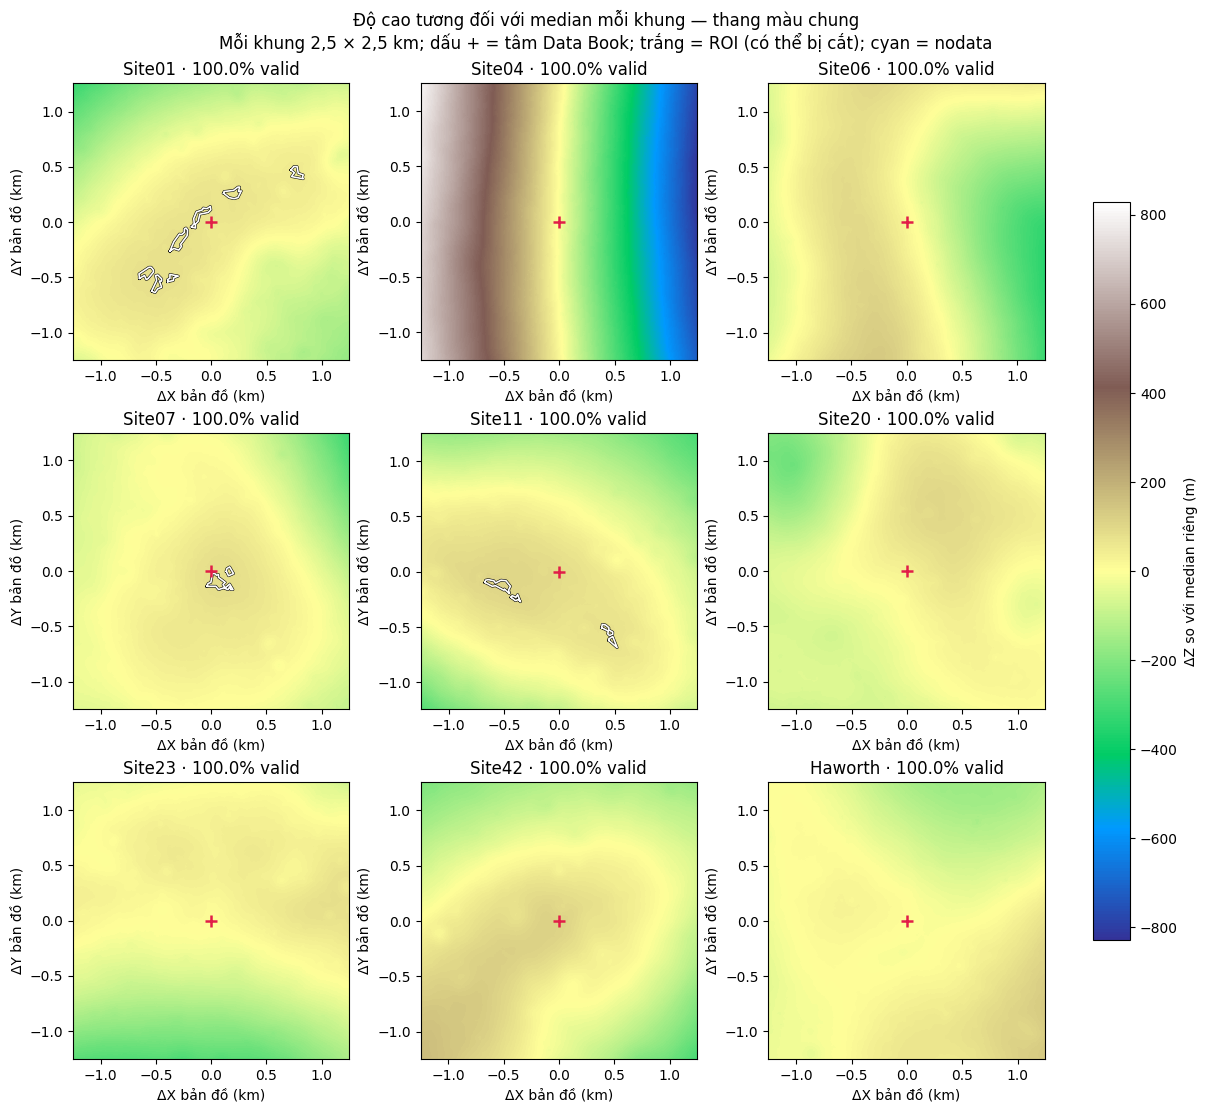

In [6]:
contact_sheet('relative')

## 2. Hình khối địa hình

Đường trắng là ROI đã giản lược và được cắt theo khung hiện tại. Khi không thấy đường trắng, có thể ROI nằm ngoài khung hoặc chưa có archive hợp lệ; kiểm tra bảng ROI và notebook vị trí trước khi kết luận.

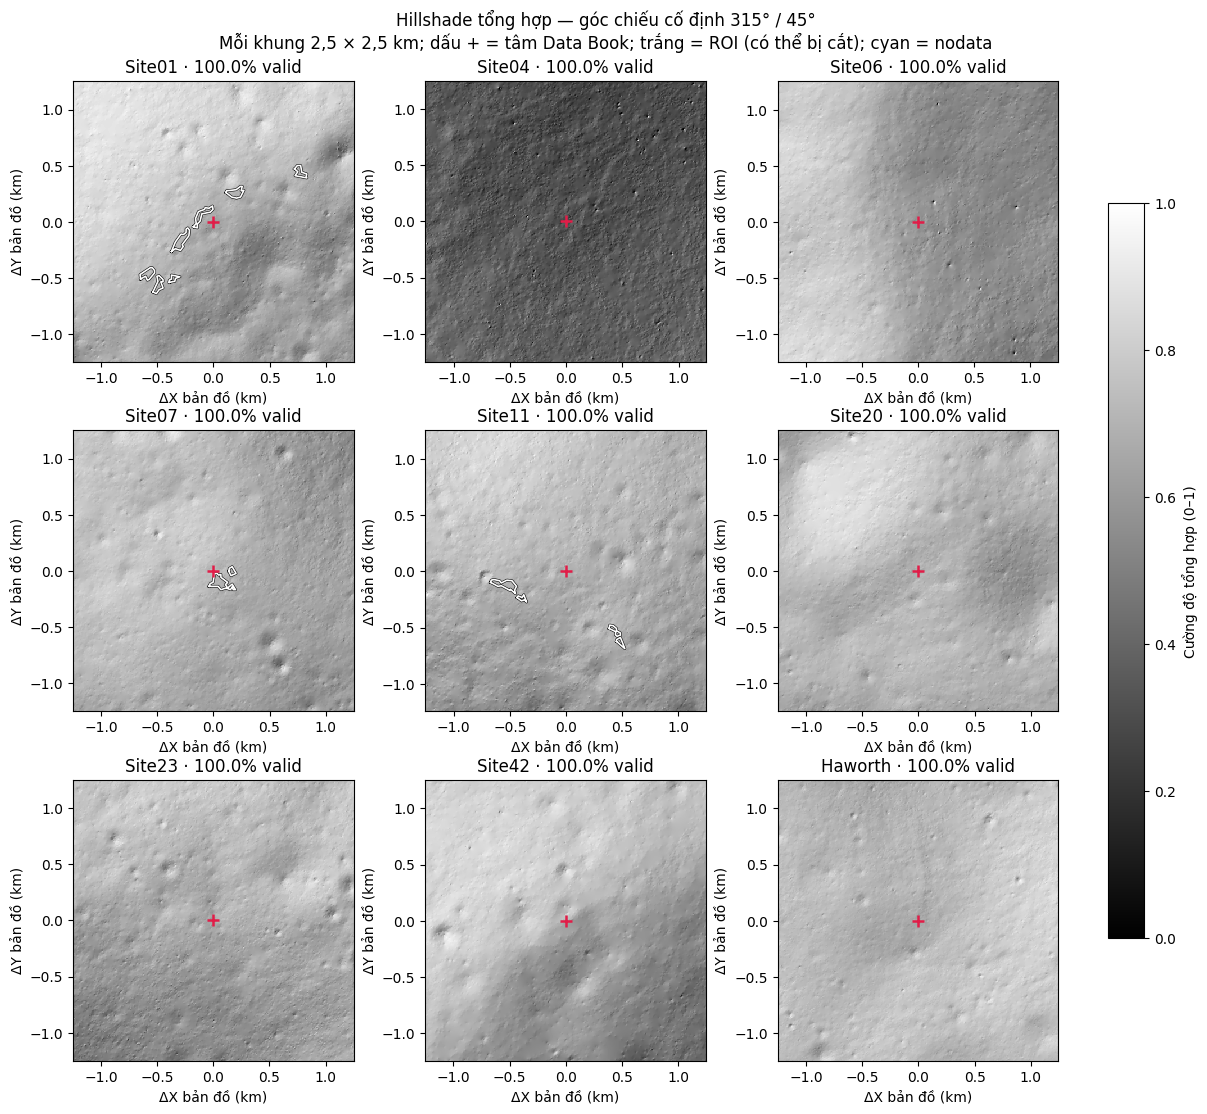

In [7]:
contact_sheet('shade')

## 3. Độ dốc ở quy mô pixel hiện tại

Độ dốc nhỏ trong khung không đủ chứng minh hạ cánh an toàn; thiếu độ nhám, vật cản dưới độ phân giải, uncertainty và yêu cầu phương tiện. Không suy ra slope RMS từ DEM đơn lẻ.

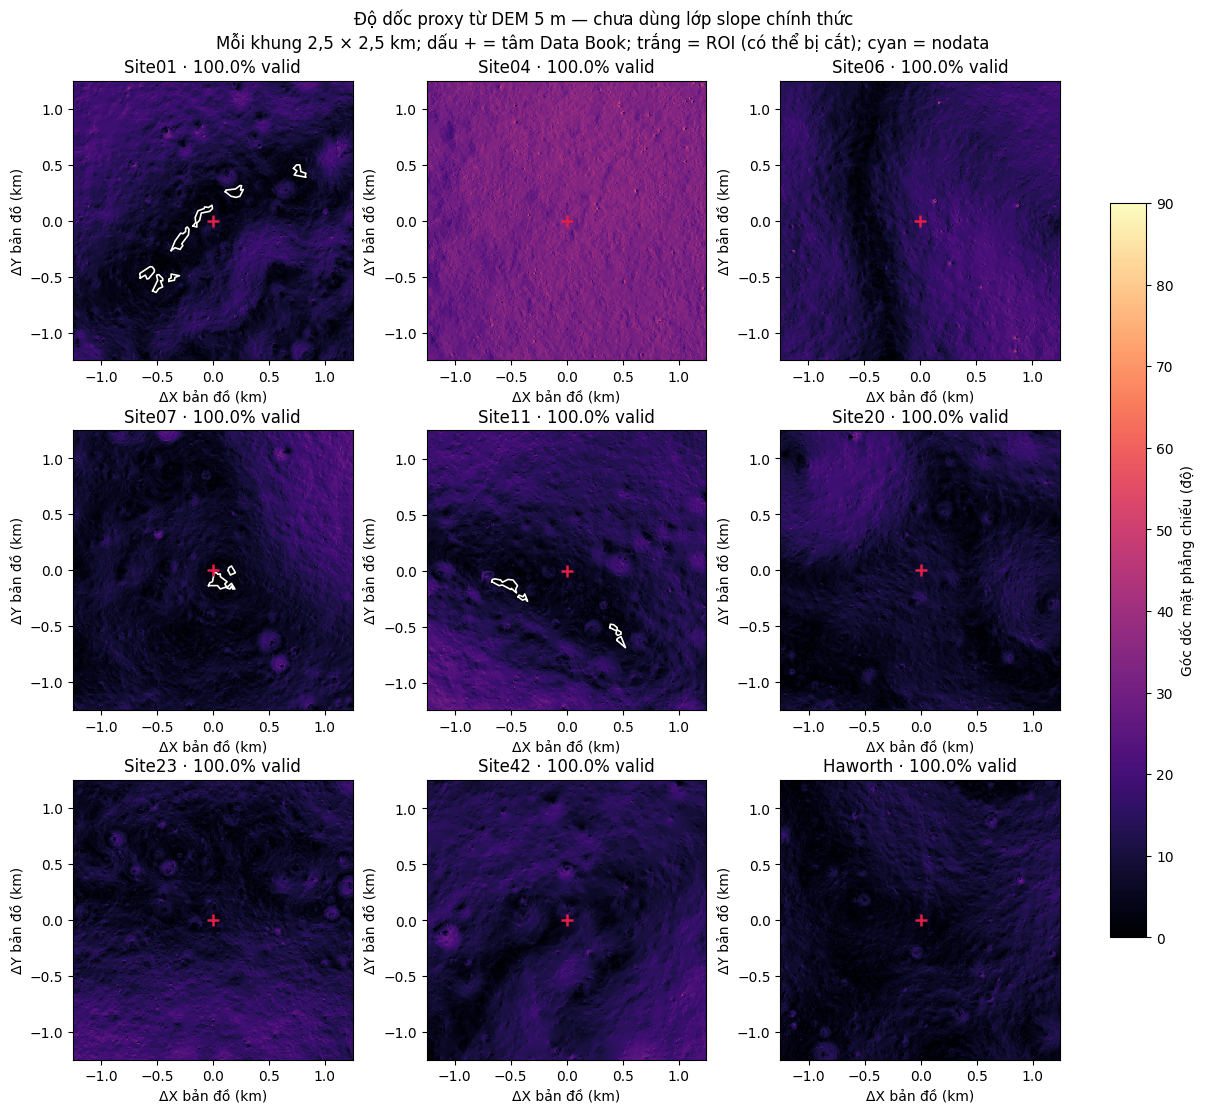

In [8]:
contact_sheet('slope')

## 4. Xem chi tiết một site

Đổi `SITE_DETAIL` thành một trong chín ID rồi chạy lại cell. Đây là tham số xem hình; không ghi quyết định chọn site. Panel mask luôn xuất hiện kể cả khi toàn bộ khung hợp lệ.

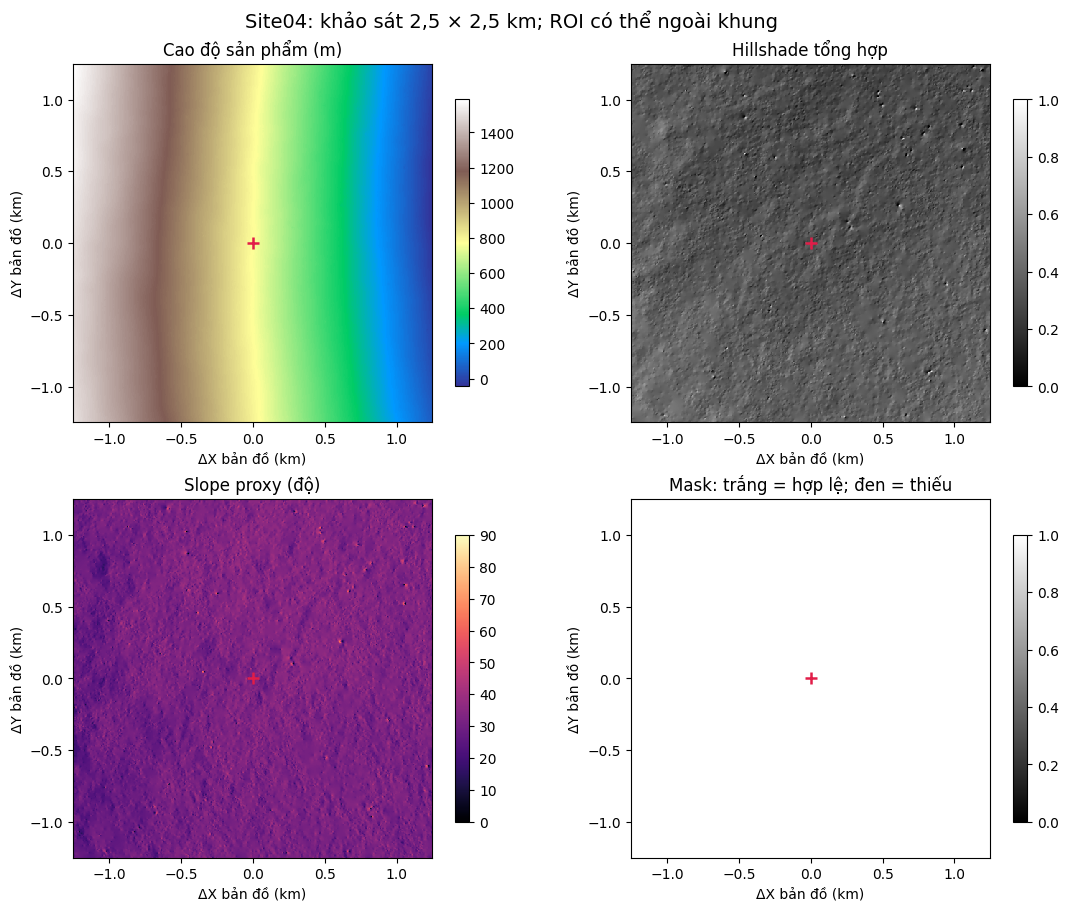

Source: https://pgda.gsfc.nasa.gov/data/LOLA_5mpp/Site04/Site04_final_adj_5mpp_surf.tif
Read at: 2026-11-14T03:16:49.625179+00:00 | bounds (m): [-2255.0, -8250.0, 245.0, -5750.0]
SHA256 crop incl. halo: 00e4d8aa1dd6049dcb5a8864bffb45bacb7419e5d3575b2b3c2f59072581ea60


In [9]:
SITE_DETAIL='Site04'
z=previews[SITE_DETAIL][1:-1,1:-1]; slope,shade=fields[SITE_DETAIL]
fig,axes=plt.subplots(2,2,figsize=(11,9),layout='constrained')
for ax,a,cmap,title in zip(axes.flat,[z,shade,slope,np.isfinite(z).astype(float)],
                         ['terrain','gray','magma','gray'],
                         ['Cao độ sản phẩm (m)','Hillshade tổng hợp','Slope proxy (độ)','Mask: trắng = hợp lệ; đen = thiếu']):
    limits={'vmin':0,'vmax':90} if 'Slope' in title else ({'vmin':0,'vmax':1} if 'Mask' in title or 'Hillshade' in title else {})
    cm=plt.get_cmap(cmap).copy(); cm.set_bad('#36d5df')
    im=ax.imshow(a,origin='upper',extent=extent_for(SITE_DETAIL),cmap=cm,interpolation='nearest',**limits)
    overlays(ax,SITE_DETAIL); ax.set_title(title); fig.colorbar(im,ax=ax,shrink=.8)
fig.suptitle(f'{SITE_DETAIL}: khảo sát 2,5 × 2,5 km; ROI có thể ngoài khung',fontsize=14)
plt.show()
m=record_by_site[SITE_DETAIL]
print('Source:',m['source_url'])
print('Read at:',m['retrieved_utc'],'| bounds (m):',m['display_bounds_m'])
print('SHA256 crop incl. halo:',m['array_sha256'])

## Nhóm cần ghi lại sau khi xem

Điền [phiếu quyết định](../docs/predecision-review.md): site cần khảo sát sâu, point/ROI và nguồn, mục tiêu demo, khoảng thời gian UTC, observer height AGL, kỳ vọng độ chính xác thời gian, ngân sách dữ liệu và người chịu trách nhiệm. Giữ các mục chưa biết là chưa quyết định.

Các mẫu mới xác minh local DEM ở Site06/Site42/Haworth trong phạm vi nhỏ; chưa kiểm tra regional 80/20 m, lớp uncertainty/count hay toàn ROI ở ba site này. Không dùng p95/chân trời lịch sử để chọn độ phân giải trước khi tái lập được kết quả. Bước sau buổi review là DE kiểm tra vùng đã chọn và cùng người phụ trách thuật toán hoàn thiện bằng chứng horizon.